## Calculate the maximum energy needed for electron and protons

In [30]:
import os
import h5py
import numpy as np
import json

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import flash_amr_tools

import astropy.units as u
import astropy.constants as const

from synch_emission_functions import t_diff, t_accel, t_adv, tcool_proton, tcool_electron
# from synch_emission_functions import t_diff, t_adv, tcool_proton, tcool_electron, mp, Ekin

Some general quantities that are the sameL:

In [31]:

# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs

pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5e}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)

Minimum & maximum of normalised momentum (electrons): 5.10999e-02 GeV, 5.10999e+03 GeV


In [32]:
vwind = 2.7e3 * u.km / u.s

Parameters and constants for cosmic rays

In [33]:
# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs
mu = 1.4  # mean molecular weight


def mom(e):
    """Normalised momentum as function of energy."""
    return np.sqrt((e + 1) ** 2 - 1)

def ekin(p):
    """Normalised kinetic energy as a function of normalised momentum"""
    return np.sqrt(p**2 + 1) - 1

def dp_dekin(p):
    """Derivative of normalised momentum wrt normalised kinetic energy."""
    return 2 * (ekin(p) + 1) / p

#### Now calculate for vstar = 40km/s

In [34]:
ekin_arr = np.logspace(np.log10(0.5), 8, 500) * u.GeV

def mom_units(ekin, mass=mp):
    """Momentum in GeV/c"""
    return np.sqrt((ekin.cgs + mass*c**2)**2 - (mass*c**2)**2) / c

pp_arr = (mom_units(ekin_arr, mass=mp) / (mp * c)).to_value(u.dimensionless_unscaled)
pe_arr = (mom_units(ekin_arr, mass=me) / (me * c)).to_value(u.dimensionless_unscaled)


# take nominal values for the density and magnetic field at the shock
# this should be calcualted using the polar timeseries data and imported for each simulation type
# and take the mean value at the outer shock
rho_val = 4e-29 * u.g / u.cm**3
B_val = 10 * u.microgauss

# vstar = 40 * u.km/u.s

diff_10GeV = 3e25 * u.cm**2 * u.s**-1

In [35]:
bowshock_config_dict = json.load(open("../../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

bs_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"

<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
1.0974950973325458e-28 g / cm3 2.916050568229957e-08 G 979.0611941019694 km / s
1.1400771283740712e-28 g / cm3 2.8789164654349313e-08 G 1002.1780942281088 km / s
1.036095420554476e-28 g / cm3 2.3880734105571128e-08 G 975.9003995259603 km / s
4.98361737242775e-28 g / cm3 3.431392818213193e-07 G 1193.893006821549 km / s


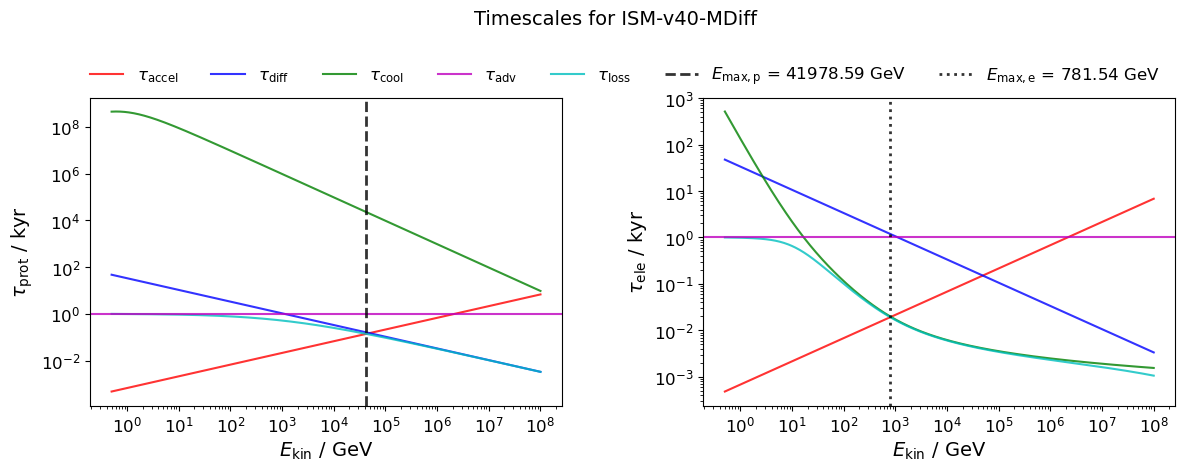

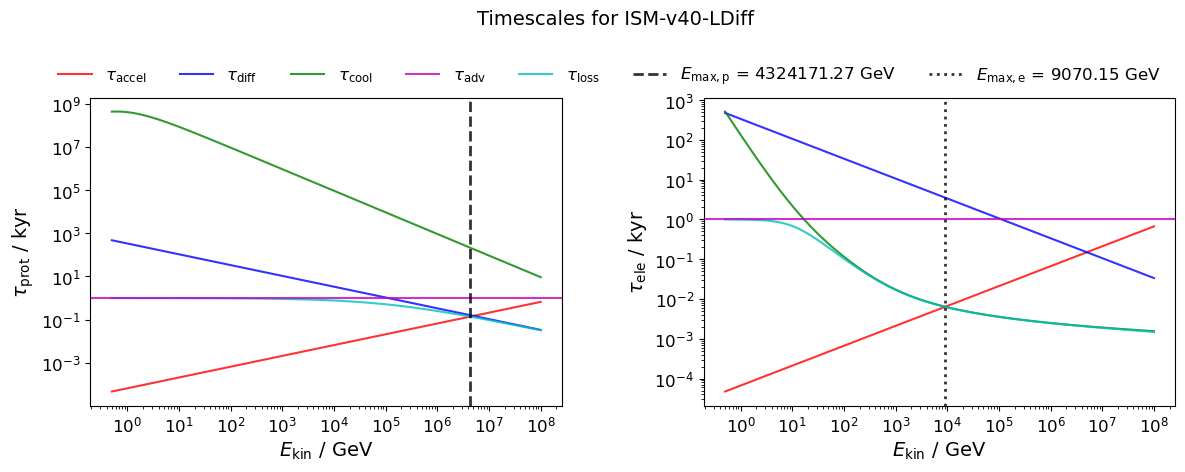

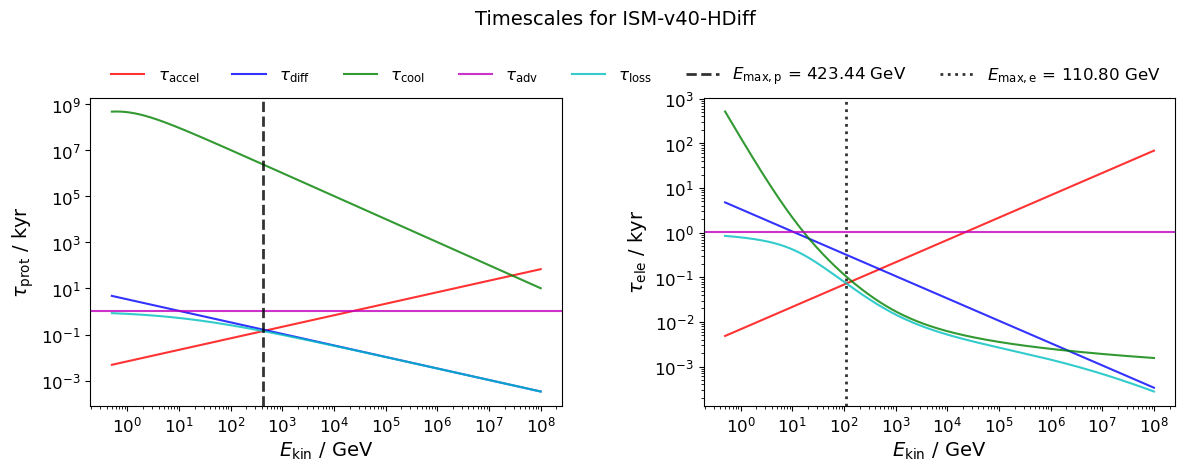

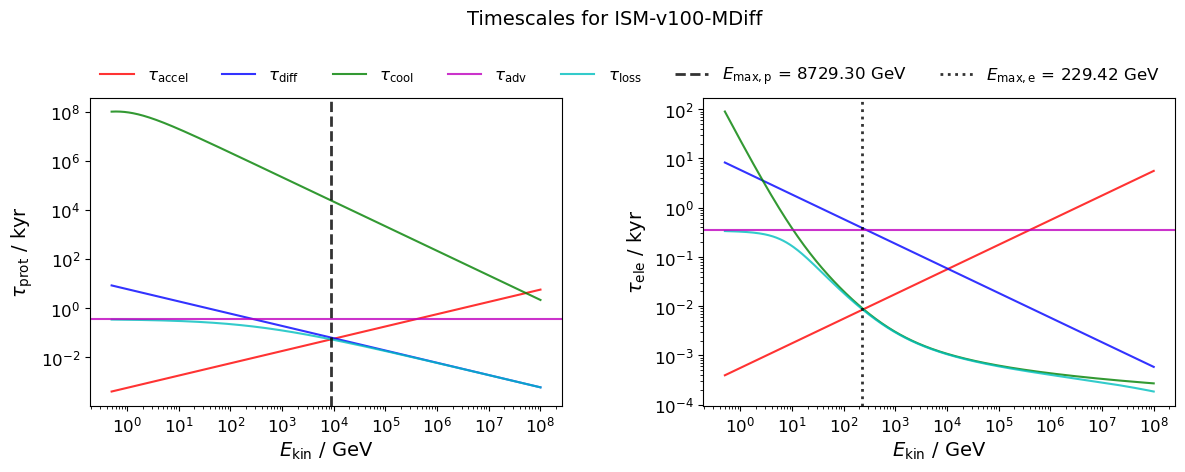

In [ ]:
emax_prots = []
emax_electrs = []
file_to_read = f"../../data/polar_time_series_term_revised.h5"
with h5py.File(file_to_read, "r") as f:

    print(f.keys())
    
    for ibs, bs_name in enumerate(bs_names):

        vstar = bowshock_config[bs_name]["vstar"] * u.km / u.s
        kappa_10 = bowshock_config[bs_name]["kappa_10"] * u.cm**2 / u.s

        dens_vals = f[bs_name]['dens'][()]
        mag_vals = f[bs_name]['mag'][()]
        vel_vals = f[bs_name]['vel'][()]
        rho_shock = np.mean(dens_vals[~np.isnan(dens_vals)]) * u.g / u.cm**3
        B_shock = np.mean(mag_vals[~np.isnan(mag_vals)]) * u.G
        vel_shock = np.mean(vel_vals[~np.isnan(vel_vals)]) * u.km/u.s
        print(rho_shock, B_shock, vel_shock)

        # claculate all times
        taccel_prot = t_accel(pp_arr, kappa_10, vel_shock, mass=mp).to(u.kyr)
        tdiff_prot = t_diff(pp_arr, vstar, kappa_10, mass=mp).to(u.kyr)
        tadv = t_adv(vel_shock, vstar).to(u.kyr)
        tcool_prot = tcool_proton(pp_arr, rho_shock).to(u.kyr)
        t_loss_prot = (1 / (1 / tcool_prot + 1 / tdiff_prot + 1 / tadv)).to(u.kyr)

        taccel_electr = t_accel(pe_arr, kappa_10, vel_shock, mass=me).to(u.kyr)
        tdiff_electr = t_diff(pe_arr, vstar, kappa_10, mass=me).to(u.kyr)
        tcool_electr = tcool_electron(pe_arr,  rho_shock, B_shock, Tstar=1e4 * u.K, vstar=vstar).to(u.kyr)
        t_loss_electr = (1 / (1 / tcool_electr + 1 / tdiff_electr + 1 / tadv)).to(u.kyr)

        fig, axs = plt.subplots(1,2,figsize=(14,4), gridspec_kw={'wspace':0.3})

        axs[0].plot(ekin_arr.to(u.GeV), taccel_prot, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), tdiff_prot, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), tcool_prot, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), t_loss_prot, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[0].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[0].set_ylabel(r"$\tau_\mathrm{prot}$ / kyr", fontsize=14)
        
        axs[1].plot(ekin_arr.to(u.GeV), taccel_electr, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), tdiff_electr, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), tcool_electr, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), t_loss_electr, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[1].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[1].set_ylabel(r"$\tau_\mathrm{ele}$ / kyr", fontsize=14)

        # finally find where taccel == tcool
        emax_prot = ekin_arr[np.argmin(np.abs(taccel_prot.value - t_loss_prot.value))]
        emax_electr = ekin_arr[np.argmin(np.abs(taccel_electr.value - t_loss_electr.value))]

        axs[0].axvline(emax_prot.to_value(u.GeV), label=rf'$E_\mathrm{{max}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0)
        axs[1].axvline(emax_electr.to_value(u.GeV), label=rf'$E_\mathrm{{max}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0)

        for ax in axs:
            ax.set_xlabel(r'$E_\mathrm{kin}$ / GeV', fontsize=14)
            ax.tick_params(axis='both', labelsize=12)
            ax.set_yscale('log')
            ax.set_xscale('log')
            # ax.set_xlim(0.5, 1e6)

        
        fig.legend(
            handles=[
                mlines.Line2D([], [], label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, p}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, e}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0),
            ],
            fontsize=12,
            ncols=7,
            frameon=False,
            bbox_to_anchor=[0.9, 1.0]
        )

        fig.suptitle(f"Timescales for {bs_name}", fontsize=14, y=1.1)

        fig.savefig(f"{fig_dir}/maximal_energy_{bs_name}.pdf", dpi=200, bbox_inches='tight')
        
        # emax_prot = ekin_arr[np.argwhere(np.isclose(taccel_prot.value, tcool_prot.value))]
        # print(emax_prot)

        emax_prots.append(emax_prot.to_value(u.GeV))
        emax_electrs.append(emax_electr.to_value(u.GeV))

emax_electrs = np.array(emax_electrs)
emax_prots = np.array(emax_prots)


Skipping ISM-v100-MDiff: dens/mag/vel have shape mismatched with times in polar_time_series_term_revised.h5 (needs regenerating).


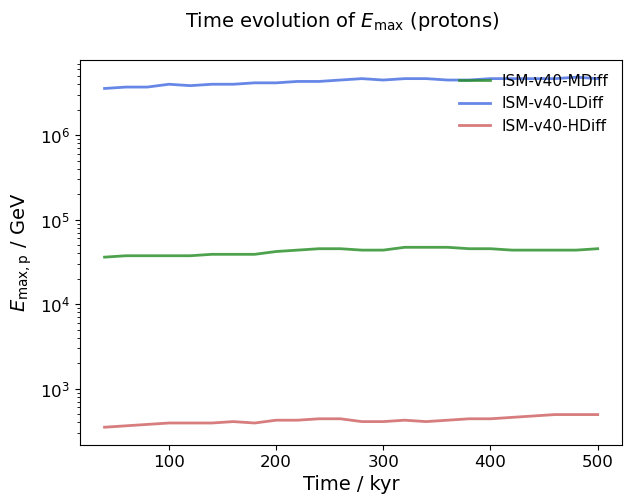

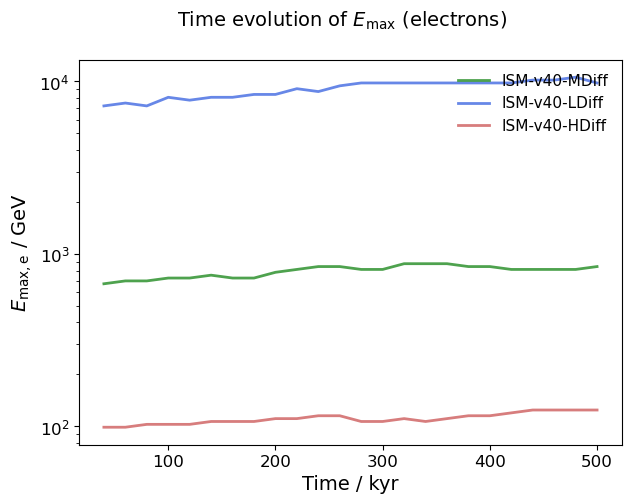

In [37]:
# Time-dependence of Emax: instead of averaging rho/B/vel over the whole time series,
# loop over each stored time and compute Emax(t) at that timestep.
# ISM-v100-MDiff is skipped for the "term" shock file: its dens/mag/vel/pres datasets
# have shape (45, 6) while times/theta_ranges (and the CR-diagnostic fields) have shape
# (26, ...) -- those 4 raw MHD fields were evidently written in a separate, later run of
# get_polar_timeseries.py that appended timesteps without updating times/theta_ranges.
# So there's no reliable way to align dens/mag/vel with times for that bs_name here; it
# should be regenerated at the source rather than papered over.

import warnings

bs_names_tdep = [bs_name for bs_name in bs_names if bs_name != "ISM-v100-MDiff"]
if len(bs_names_tdep) < len(bs_names):
    print(
        "Skipping ISM-v100-MDiff: dens/mag/vel have shape mismatched with times "
        "in polar_time_series_term_revised.h5 (needs regenerating)."
    )

times_dict = {}
emax_prot_t_dict = {}
emax_electr_t_dict = {}

with h5py.File(file_to_read, "r") as f:

    for ibs, bs_name in enumerate(bs_names_tdep):

        vstar = bowshock_config[bs_name]["vstar"] * u.km / u.s
        kappa_10 = bowshock_config[bs_name]["kappa_10"] * u.cm**2 / u.s

        times = f[bs_name]['times'][()] * u.s

        dens_vals = f[bs_name]['dens'][()]
        mag_vals = f[bs_name]['mag'][()]
        vel_vals = f[bs_name]['vel'][()]

        # average over the theta bins (axis=-1) at each timestep, ignoring nans
        # (early timesteps before the shock has formed can be all-nan across theta bins,
        # which np.nanmean turns into nan with a "Mean of empty slice" warning -- expected,
        # handled explicitly below)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Mean of empty slice")
            rho_shock_t = np.nanmean(dens_vals, axis=-1) * u.g / u.cm**3
            B_shock_t = np.nanmean(mag_vals, axis=-1) * u.G
            vel_shock_t = np.nanmean(vel_vals, axis=-1) * u.km / u.s

        emax_prot_t = np.full(len(times), np.nan) * u.GeV
        emax_electr_t = np.full(len(times), np.nan) * u.GeV

        for it in range(len(times)):

            rho_shock = rho_shock_t[it]
            B_shock = B_shock_t[it]
            vel_shock = vel_shock_t[it]

            # skip timesteps before the shock has formed, where all theta bins are nan
            # (otherwise argmin on an all-nan array would silently return index 0)
            if np.isnan(rho_shock) or np.isnan(B_shock) or np.isnan(vel_shock):
                continue

            taccel_prot = t_accel(pp_arr, kappa_10, vel_shock, mass=mp).to(u.kyr)
            tdiff_prot = t_diff(pp_arr, vstar, kappa_10, mass=mp).to(u.kyr)
            tadv = t_adv(vel_shock, vstar).to(u.kyr)
            tcool_prot = tcool_proton(pp_arr, rho_shock).to(u.kyr)
            t_loss_prot = (1 / (1 / tcool_prot + 1 / tdiff_prot + 1 / tadv)).to(u.kyr)

            taccel_electr = t_accel(pe_arr, kappa_10, vel_shock, mass=me).to(u.kyr)
            tdiff_electr = t_diff(pe_arr, vstar, kappa_10, mass=me).to(u.kyr)
            tcool_electr = tcool_electron(pe_arr, rho_shock, B_shock, Tstar=1e4 * u.K, vstar=vstar).to(u.kyr)
            t_loss_electr = (1 / (1 / tcool_electr + 1 / tdiff_electr + 1 / tadv)).to(u.kyr)

            emax_prot_t[it] = ekin_arr[np.argmin(np.abs(taccel_prot.value - t_loss_prot.value))]
            emax_electr_t[it] = ekin_arr[np.argmin(np.abs(taccel_electr.value - t_loss_electr.value))]

        times_dict[bs_name] = times.to(u.kyr)
        emax_prot_t_dict[bs_name] = emax_prot_t
        emax_electr_t_dict[bs_name] = emax_electr_t

# --- overlay plot: protons ---
fig, ax = plt.subplots(figsize=(7, 5))
for bs_name in bs_names_tdep:
    ax.plot(
        times_dict[bs_name],
        emax_prot_t_dict[bs_name],
        label=bowshock_config[bs_name]["label"],
        color=bowshock_config[bs_name]["color"],
        lw=2.0,
        alpha=0.8,
    )
ax.set_xlabel("Time / kyr", fontsize=14)
ax.set_ylabel(r"$E_\mathrm{max, p}$ / GeV", fontsize=14)
ax.set_yscale('log')
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=11, frameon=False)
fig.suptitle(r"Time evolution of $E_\mathrm{max}$ (protons)", fontsize=14)
fig.savefig(f"{fig_dir}/maximal_energy_protons_timeseries.pdf", dpi=200, bbox_inches='tight')

# --- overlay plot: electrons ---
fig, ax = plt.subplots(figsize=(7, 5))
for bs_name in bs_names_tdep:
    ax.plot(
        times_dict[bs_name],
        emax_electr_t_dict[bs_name],
        label=bowshock_config[bs_name]["label"],
        color=bowshock_config[bs_name]["color"],
        lw=2.0,
        alpha=0.8,
    )
ax.set_xlabel("Time / kyr", fontsize=14)
ax.set_ylabel(r"$E_\mathrm{max, e}$ / GeV", fontsize=14)
ax.set_yscale('log')
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=11, frameon=False)
fig.suptitle(r"Time evolution of $E_\mathrm{max}$ (electrons)", fontsize=14)
fig.savefig(f"{fig_dir}/maximal_energy_electrons_timeseries.pdf", dpi=200, bbox_inches='tight')


In [38]:
bs_names

['ISM-v40-MDiff', 'ISM-v40-LDiff', 'ISM-v40-HDiff', 'ISM-v100-MDiff']

In [39]:
print("emax_prots =", emax_prots, " GeV")
print("emax_electrs =", emax_electrs, " GeV")

emax_prots = [4.19785929e+04 4.32417127e+06 4.23436410e+02 8.72929802e+03]  GeV
emax_electrs = [ 781.54410138 9070.15380168  110.80302736  229.41558027]  GeV


In [40]:
pmax_prot = mom(emax_prots / (mp * c**2).to_value(u.GeV))
pmax_electr = mom(emax_electrs / (me * c**2).to_value(u.GeV))

print("pmax_prot =", pmax_prot, " / (mpc)")
print("pmax_electr =", pmax_electr, " / (mec)")

pmax_prot = [4.47413194e+04 4.60865484e+06 4.52292731e+02 9.30458910e+03]  / (mpc)
pmax_electr = [ 1529444.65420474 17749849.21739545   216837.1155385    448956.09134552]  / (mec)


#### Print Emax and pmax in a nice, manuscript-ready table

In [41]:
import math


def fmt_value(x, sig=3):
    """Format a number with `sig` significant figures; switch to scientific
    notation (mantissa x 10^exp) once the integer part exceeds 6 digits."""
    if x == 0 or np.isnan(x):
        return f"{x}"

    ndigits_int = len(str(int(abs(x))))

    if ndigits_int > 6:
        mantissa, exp = f"{x:.{sig - 1}e}".split("e")
        return f"{mantissa}e{int(exp):+03d}"
    else:
        decimals = max(sig - ndigits_int, 0)
        return f"{x:.{decimals}f}"


# column widths
name_w = max(len(name) for name in bs_names) + 2
col_w = 16

header = (
    f"{'Bowshock':<{name_w}}"
    f"{'Emax_p [GeV]':>{col_w}}"
    f"{'Emax_e [GeV]':>{col_w}}"
    f"{'pmax_p [m_p c]':>{col_w}}"
    f"{'pmax_e [m_e c]':>{col_w}}"
)
print(header)
print("-" * len(header))

for name, ep, ee, pp, pe in zip(bs_names, emax_prots, emax_electrs, pmax_prot, pmax_electr):
    print(
        f"{name:<{name_w}}"
        f"{fmt_value(ep):>{col_w}}"
        f"{fmt_value(ee):>{col_w}}"
        f"{fmt_value(pp):>{col_w}}"
        f"{fmt_value(pe):>{col_w}}"
    )


Bowshock            Emax_p [GeV]    Emax_e [GeV]  pmax_p [m_p c]  pmax_e [m_e c]
--------------------------------------------------------------------------------
ISM-v40-MDiff              41979             782           44741        1.53e+06
ISM-v40-LDiff           4.32e+06            9070        4.61e+06        1.77e+07
ISM-v40-HDiff                423             111             452          216837
ISM-v100-MDiff              8729             229            9305          448956


#### Write pmax_prot and pmax_electr back into bowshock_config.json

In [42]:
config_path = "../../config/bowshock_config.json"

# re-read from disk so we don't clobber any changes made elsewhere since
# bowshock_config_dict was first loaded
with open(config_path, "r") as fjson:
    bowshock_config_dict_out = json.load(fjson)

for name, pp, pe in zip(bs_names, pmax_prot, pmax_electr):
    bowshock_config_dict_out["config"][name]["pmax_prot"] = float(pp)
    bowshock_config_dict_out["config"][name]["pmax_electr"] = float(pe)

with open(config_path, "w") as fjson:
    json.dump(bowshock_config_dict_out, fjson, indent=4)

print(f"Wrote pmax_prot / pmax_electr for {bs_names} to {config_path}")


Wrote pmax_prot / pmax_electr for ['ISM-v40-MDiff', 'ISM-v40-LDiff', 'ISM-v40-HDiff', 'ISM-v100-MDiff'] to ../../config/bowshock_config.json
